# Training a multilayer perceptron from scratch, in JAX

Build an MLP out of nothing but arrays — the parameters, the forward pass, the optimizers, and the training
loop. `jax.grad` gives you backpropagation; write everything else yourself.

The target is a sum of four sine waves of **equal amplitude** at frequencies 1, 2, 4 and 8. 

In [1]:
# !pip install -q jax jaxlib matplotlib

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

print("jax", jax.__version__, "| devices:", jax.devices())

jax 0.11.2 | devices: [CpuDevice(id=0)]


## The data


In [2]:
FREQS = jnp.array([1.0, 2.0, 4.0, 8.0])
NOISE_STD = 0.02


def target_fn(x):
    """x: (n,) -> (n,)"""
    return jnp.mean(jnp.sin(2 * jnp.pi * FREQS * x[:, None]), axis=-1)


def make_data(key, n=2048, noise_std=NOISE_STD):
    """Returns X: (n, 1), Y: (n, 1)"""
    key_x, key_noise = jax.random.split(key)
    x = jax.random.uniform(key_x, (n,), minval=0.0, maxval=1.0)
    y = target_fn(x) + noise_std * jax.random.normal(key_noise, (n,))
    return x[:, None], y[:, None]


X, Y = make_data(jax.random.key(0))

print(f"target variance : {float(Y.var()):.4f}")   # silly baseline: the error you get by predicting the mean

target variance : 0.1236


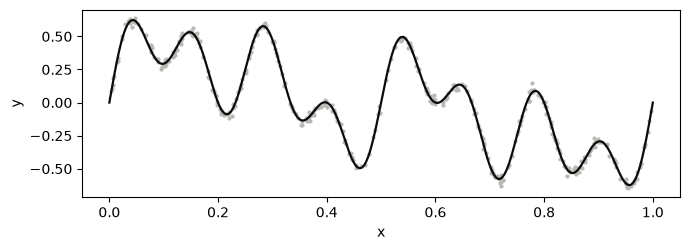

In [3]:
grid = jnp.linspace(0, 1, 1000)
plt.figure(figsize=(7, 2.6))
plt.scatter(np.array(X[:400, 0]), np.array(Y[:400, 0]), s=4, color="#b8b8b4")
plt.plot(np.array(grid), np.array(target_fn(grid)), color="#0b0b0b", lw=1.6)
plt.xlabel("x"); plt.ylabel("y"); plt.tight_layout(); plt.show()

---
## 1. The network

Write three functions:

- `init_mlp(key, layer_sizes)` — the parameters. Think about what a layer actually *is*, and about the scale
  of the initial random draw.
- `forward(params, x)` — `activation` on the hidden layers, nothing on the output.
- `loss_fn(params, x, y)` — mean squared error.

Use `[1, 128, 128, 1]`.

In [4]:
def init_mlp(key, layer_sizes):
    keys = jax.random.split(key, len(layer_sizes) - 1)
    params = []
    for i in range(len(layer_sizes) - 1):
        w_key, b_key = jax.random.split(keys[i])
        w = jax.random.normal(w_key, (layer_sizes[i], layer_sizes[i + 1]))
        w *= jnp.sqrt(2.0 / layer_sizes[i])
        b = jnp.zeros((layer_sizes[i + 1],))
        params.append((w, b))
    return params

@jax.jit
def forward(params, x):
    for w, b in params[:-1]:
        h = jnp.dot(x, w) + b
        x = jax.nn.relu(h)
    w, b = params[-1]
    return jnp.dot(x, w) + b

@jax.jit
def loss_fn(params, x, y):
    y_pred = forward(params, x)
    return jnp.mean((y_pred - y) ** 2)

---
## 2. The training loop

Minibatches of 128, reshuffled every epoch, 400 epochs. Get gradients with `jax.grad`. Wrap the step in
`@jax.jit` or it will be slow.

In [5]:
# 8192 total samples, 128 samples per batch, 64 batches
BATCH_SIZE = 128
N_BATCHES = 64
DATA_SIZE = BATCH_SIZE * N_BATCHES

X_dataset, Y_dataset = make_data(jax.random.key(1), n=DATA_SIZE)

def train_loop(key, params, update_fn, n_epochs=400, batch_size=128, n_batches = 64, lr=1e-3):
    losses = np.zeros((n_epochs, n_batches))
    for epoch in range(n_epochs):
        key, subkey = jax.random.split(key)
        x_batches_flat = jnp.reshape(X_dataset, (n_batches * batch_size, 1))
        y_batches_flat = jnp.reshape(Y_dataset, (n_batches * batch_size, 1))

        # Shuffle the batches for each epoch
        perm = jax.random.permutation(subkey, n_batches * batch_size)
        x_batches_flat = x_batches_flat[perm]
        y_batches_flat = y_batches_flat[perm]

        # Reshape back to batches
        X_batches = jnp.reshape(x_batches_flat, (n_batches, batch_size, 1))
        Y_batches = jnp.reshape(y_batches_flat, (n_batches, batch_size, 1))

        avg_loss = 0

        for i in range(n_batches):
            x_batch = X_batches[i]
            y_batch = Y_batches[i]
            params = update_fn(params, x_batch, y_batch, lr=lr)
            loss = loss_fn(params, x_batch, y_batch)
            avg_loss += loss
            losses[epoch, i] = loss
        print(f"\repoch {epoch + 1}/{n_epochs}, average loss: {float(avg_loss) / n_batches:.6f}", end="")
    return params, losses


---
## 3. The optimizers

Implement each one from its update equation:

1. **Gradient descent** — full batch, one step per epoch
2. **SGD** — minibatch
3. **SGD with momentum**
4. **Adagrad**
5. **Adam**
6. **Muon** — if you get that far, but it is waaaay trickier so don't get discouraged if you stop at Adam!

Look the update rules up. Muon is recent and not in textbooks:
[kellerjordan.github.io/posts/muon](https://kellerjordan.github.io/posts/muon/).

### A. Gradient Descent

In [6]:
@jax.jit
def grad_descent(params, x, y, lr=1e-3):
    grads = jax.grad(loss_fn)(params, x, y)
    return [(w - lr * dw, b - lr * db) for (w, b), (dw, db) in zip(params, grads)]

mlp = init_mlp(jax.random.key(3), [1, 128, 128, 1])
first_grad = jax.grad(loss_fn)(mlp, X_dataset[:10], Y_dataset[:10])
# Get MLP shape
print("MLP shape:", [(w.shape, b.shape) for w, b in mlp])
# Get first gradient shape
print("First gradient shape:", [(dw.shape, db.shape) for dw, db in first_grad])
print("initial loss:", float(loss_fn(mlp, X_dataset[:10], Y_dataset[:10])))
key = jax.random.PRNGKey(0)

lrs = np.logspace(1, -5, 12)
grad_descent_loss_vs_lr = []
min_loss = np.inf
grad_descent_best_lr = None
for lr_i in lrs:
    final_mlp, losses = train_loop(key, mlp, grad_descent, n_epochs=400, n_batches=1, batch_size=DATA_SIZE, lr=lr_i)
    final_loss = np.mean(losses[-1])

    # Get best learning rate based on final loss
    if final_loss < min_loss:
        min_loss = final_loss
        grad_descent_best_lr = lr_i
        grad_descent_mlp = final_mlp
        grad_descent_losses = losses
    
    grad_descent_loss_vs_lr.append(final_loss)
    print(f"\n lr: {lr_i:.1e}, final loss: {final_loss:.6f}")

print(f"Best learning rate for gradient descent: {grad_descent_best_lr:.1e}, final loss: {min_loss:.6f}")

MLP shape: [((1, 128), (128,)), ((128, 128), (128,)), ((128, 1), (1,))]
First gradient shape: [((1, 128), (128,)), ((128, 128), (128,)), ((128, 1), (1,))]
initial loss: 0.11397122591733932
epoch 400/400, average loss: nan435412565635407413697293844480.000000
 lr: 1.0e+01, final loss: nan
epoch 400/400, average loss: nan7581786112.000000
 lr: 2.8e+00, final loss: nan
epoch 400/400, average loss: nan69575601435836416.000000
 lr: 8.1e-01, final loss: nan
epoch 400/400, average loss: 0.12605636100000000000000
 lr: 2.3e-01, final loss: 0.126056
epoch 400/400, average loss: 0.051280
 lr: 6.6e-02, final loss: 0.051280
epoch 400/400, average loss: 0.057691
 lr: 1.9e-02, final loss: 0.057691
epoch 400/400, average loss: 0.058329
 lr: 5.3e-03, final loss: 0.058329
epoch 400/400, average loss: 0.069164
 lr: 1.5e-03, final loss: 0.069164
epoch 400/400, average loss: 0.089176
 lr: 4.3e-04, final loss: 0.089176
epoch 400/400, average loss: 0.099994
 lr: 1.2e-04, final loss: 0.099994
epoch 400/400, a

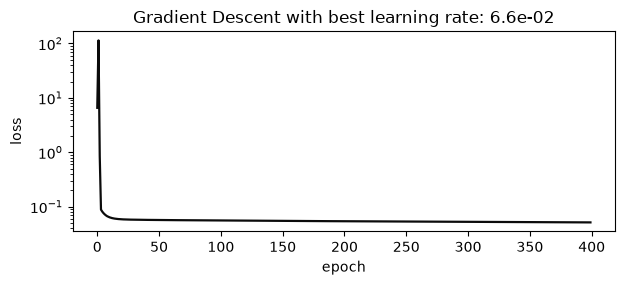

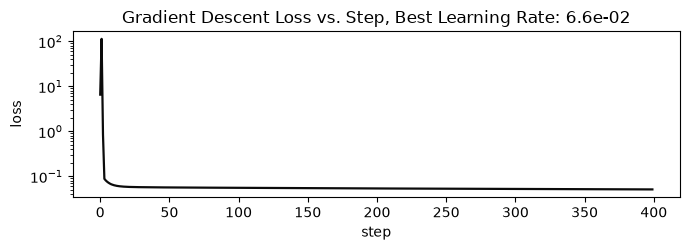

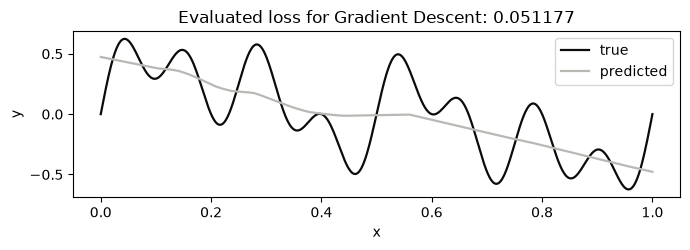

In [7]:
def present_data(losses, mlp, best_lr, method_name):
    # Plot loss vs. epoch
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.plot(losses.mean(axis=1), color="#0b0b0b", lw=1.6)
    ax.set_xlabel("epoch"); 
    ax.set_yscale("log")
    ax.set_ylabel("loss")
    ax.set_title(f"{method_name} with best learning rate: {best_lr:.1e}")

    # Plot loss vs. step
    fig2, ax2 = plt.subplots(figsize=(7, 2.6))
    ax2.set_xlabel("step");
    ax2.plot(losses.flatten(), color="#0b0b0b", lw=1.6)
    ax2.set_yscale("log")
    ax2.set_ylabel("loss")
    ax2.set_title(f"{method_name} Loss vs. Step, Best Learning Rate: {best_lr:.1e}")
    plt.tight_layout()
    plt.show()

    # Plot predicted vs. true function
    fig2, ax2 = plt.subplots(figsize=(7, 2.6))
    t = np.linspace(0, 1, 1000)
    y_pred = np.array(forward(mlp, t[:, None]))[:, 0]
    y_true = np.array(target_fn(t))
    ax2.plot(t, y_true, color="#0b0b0b", lw=1.6, label="true")
    ax2.plot(t, y_pred, color="#b8b8b4", lw=1.6, label="predicted")
    ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.legend()

    # Calculate loss on validation set t
    validation_loss = np.mean((y_pred - y_true) ** 2)
    ax2.set_title(f"Evaluated loss for {method_name}: {validation_loss:.6f}")
    plt.tight_layout()
    plt.show()
present_data(grad_descent_losses, grad_descent_mlp, grad_descent_best_lr, "Gradient Descent")

### B. SGD with Minibatch

In [8]:
BATCH_SIZE = 128
mlp = init_mlp(jax.random.key(3), [1, 128, 128, 1])

sgd_minibatch_losses_vs_lr = []
min_loss = np.inf
sgd_minibatch_best_lr = None
for lr_i in lrs:

    # Collect loss for lr
    final_mlp, losses = train_loop(jax.random.key(4), mlp, grad_descent, n_epochs=400, n_batches=N_BATCHES, batch_size=BATCH_SIZE, lr=lr_i)
    final_loss = np.mean(losses[-1])

    # Save run with the best loss
    if final_loss < min_loss:
        min_loss = final_loss
        sgd_minibatch_mlp = final_mlp
        sgd_minibatch_losses = losses
        sgd_minibatch_best_lr = lr_i
        
    sgd_minibatch_losses_vs_lr.append(final_loss)
    print(f"\r lr: {lr_i:.1e}, final loss: {final_loss:.6f}")

print("Best run: lr:", sgd_minibatch_best_lr, "final loss:", min_loss)

 lr: 1.0e+01, final loss: nannan
 lr: 2.8e+00, final loss: nannan
 lr: 8.1e-01, final loss: nannan
 lr: 2.3e-01, final loss: 0.125503503
 lr: 6.6e-02, final loss: 0.020318318
 lr: 1.9e-02, final loss: 0.055424424
 lr: 5.3e-03, final loss: 0.055781781
 lr: 1.5e-03, final loss: 0.057009009
 lr: 4.3e-04, final loss: 0.057539539
 lr: 1.2e-04, final loss: 0.057970970
 lr: 3.5e-05, final loss: 0.063689689
 lr: 1.0e-05, final loss: 0.083614614
Best run: lr: 0.06579332246575682 final loss: 0.020317524002166465


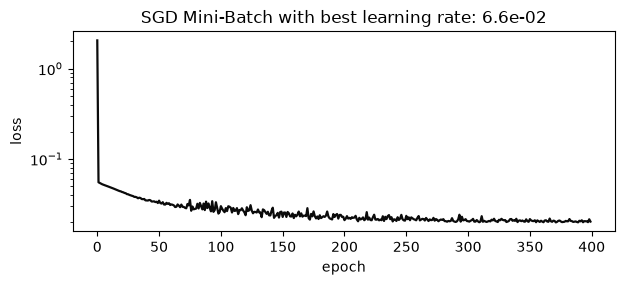

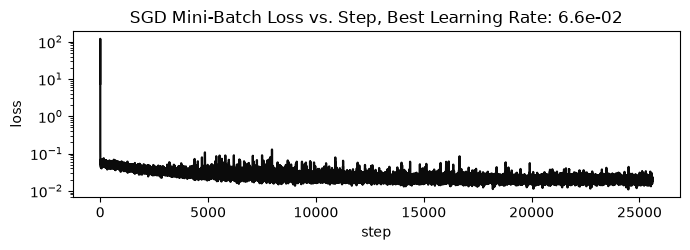

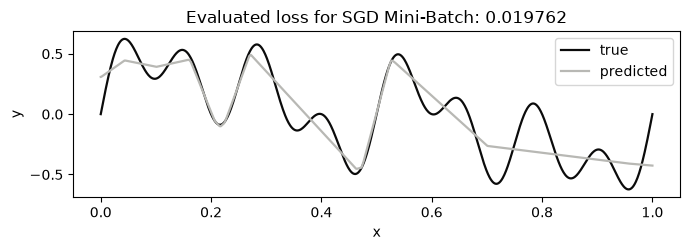

In [9]:
# Plot loss vs. epoch
present_data(sgd_minibatch_losses, sgd_minibatch_mlp, sgd_minibatch_best_lr, "SGD Mini-Batch")

### C. SGD with Momentum

In [10]:
@jax.jit
def sgd_update(params, x, y, old_grad, lr=1e-3, average_rate=0.9):
    grads = jax.grad(loss_fn)(params, x, y)
    grads = [(average_rate * old_w + (1 - average_rate) * w, 
              average_rate * old_b + (1 - average_rate) * b) for ((old_w, old_b), (w, b)) in zip(old_grad, grads)]
    return [(w - lr * dw, b - lr * db) for (w, b), (dw, db) in zip(params, grads)], grads

def train_loop_with_sgd_momentum(key, params, n_epochs=400, batch_size=128, n_batches = 64, lr=1e-3):
    losses = np.zeros((n_epochs, n_batches))
    old_grad = [(jnp.zeros_like(w), jnp.zeros_like(b)) for w, b in params]

    for epoch in range(n_epochs):
        key, subkey = jax.random.split(key)
        x_batches_flat = jnp.reshape(X_dataset, (n_batches * batch_size, 1))
        y_batches_flat = jnp.reshape(Y_dataset, (n_batches * batch_size, 1))

        # Shuffle the batches for each epoch
        perm = jax.random.permutation(subkey, n_batches * batch_size)
        x_batches_flat = x_batches_flat[perm]
        y_batches_flat = y_batches_flat[perm]

        # Reshape back to batches
        X_batches = jnp.reshape(x_batches_flat, (n_batches, batch_size, 1))
        Y_batches = jnp.reshape(y_batches_flat, (n_batches, batch_size, 1))

        avg_loss = 0
        for i in range(n_batches):
            x_batch = X_batches[i]
            y_batch = Y_batches[i]
            params, old_grad = sgd_update(params, x_batch, y_batch, old_grad, lr=lr)
            loss = loss_fn(params, x_batch, y_batch)
            avg_loss += loss
            losses[epoch, i] = loss
        print(f"\repoch {epoch + 1}/{n_epochs}, average loss: {float(avg_loss) / n_batches:.6f}", end="")
    return params, losses


mlp = init_mlp(jax.random.key(3), [1, 128, 128, 1])

sgd_momentum_loss_vs_lr = []
sgd_momentum_best_lr = None
min_loss = np.inf
for lr_i in lrs:
    final_mlp, losses = train_loop_with_sgd_momentum(jax.random.key(5), mlp, n_epochs=400, n_batches=N_BATCHES, batch_size=BATCH_SIZE, lr=lr_i)
    final_loss = np.mean(losses[-1])

    if final_loss < min_loss:
        min_loss = final_loss
        sgd_momentum_best_lr = lr_i
        sgd_momentum_mlp = final_mlp
        sgd_momentum_losses = losses
    sgd_momentum_loss_vs_lr.append(final_loss)
    print(f"\r lr: {lr_i:.1e}, final loss: {final_loss:.6f}")

print(f"Best learning rate for SGD with momentum: {sgd_momentum_best_lr:.1e}, final loss: {min_loss:.6f}")

 lr: 1.0e+01, final loss: nannan
 lr: 2.8e+00, final loss: 0.127673673
 lr: 8.1e-01, final loss: 0.128558558
 lr: 2.3e-01, final loss: 0.016923923
 lr: 6.6e-02, final loss: 0.055421421
 lr: 1.9e-02, final loss: 0.056703703
 lr: 5.3e-03, final loss: 0.056298298
 lr: 1.5e-03, final loss: 0.057146146
 lr: 4.3e-04, final loss: 0.057573573
 lr: 1.2e-04, final loss: 0.057981981
 lr: 3.5e-05, final loss: 0.063693693
 lr: 1.0e-05, final loss: 0.083624624
Best learning rate for SGD with momentum: 2.3e-01, final loss: 0.016923


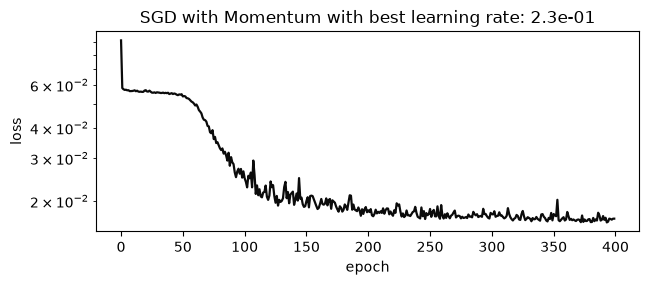

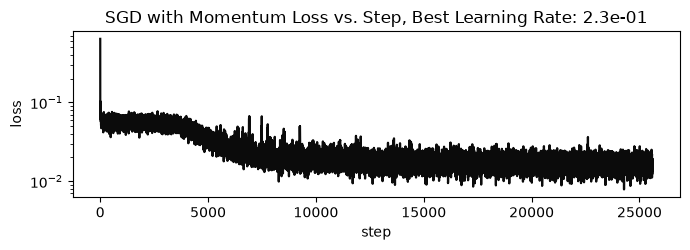

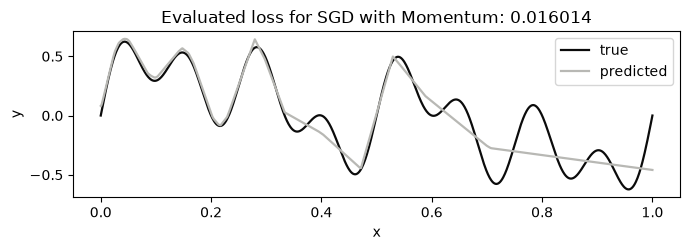

In [11]:
present_data(sgd_momentum_losses, sgd_momentum_mlp, sgd_momentum_best_lr, "SGD with Momentum")

### D. Adagrad

In [12]:
EPSILON = 1e-8

@jax.jit
def adagrad_update(params, x, y, g, lr=1e-3, epsilon=EPSILON):
    grads = jax.grad(loss_fn)(params, x, y)
    g = [(gw + dw ** 2, gb + db ** 2) for (gw, gb), (dw, db) in zip(g, grads)]
    grads = [((lr / jnp.sqrt(g_w + epsilon)) * w, (lr / jnp.sqrt(g_b + epsilon)) * b) for (g_w, g_b), (w, b) in zip(g, grads)]
    params = [(w - dw, b - db) for (w, b), (dw, db) in zip(params, grads)]
    return params, g

def train_loop_with_adagrad(key, params, n_epochs=400, batch_size=128, n_batches = 64, lr=1e-3):
    losses = np.zeros((n_epochs, n_batches))
    g = [(jnp.zeros_like(w), jnp.zeros_like(b)) for w, b in params]

    for epoch in range(n_epochs):
        key, subkey = jax.random.split(key)
        x_batches_flat = jnp.reshape(X_dataset, (n_batches * batch_size, 1))
        y_batches_flat = jnp.reshape(Y_dataset, (n_batches * batch_size, 1))

        # Shuffle the batches for each epoch
        perm = jax.random.permutation(subkey, n_batches * batch_size)
        x_batches_flat = x_batches_flat[perm]
        y_batches_flat = y_batches_flat[perm]

        # Reshape back to batches
        X_batches = jnp.reshape(x_batches_flat, (n_batches, batch_size, 1))
        Y_batches = jnp.reshape(y_batches_flat, (n_batches, batch_size, 1))

        avg_loss = 0
        for i in range(n_batches):
            # Collect losses for this batch
            x_batch = X_batches[i]
            y_batch = Y_batches[i]
            params, g = adagrad_update(params, x_batch, y_batch, g, lr=lr)
            loss = loss_fn(params, x_batch, y_batch)
            avg_loss += loss
            losses[epoch, i] = loss
        print(f"\repoch {epoch + 1}/{n_epochs}, average loss: {float(avg_loss) / n_batches:.6f}", end="")
    return params, losses

adagrad_mlp_loss_vs_lr = []
min_loss = np.inf
adagrad_best_lr = None
for lr_i in lrs:
    final_mlp, losses = train_loop_with_adagrad(jax.random.key(6), mlp, n_epochs=400, n_batches=N_BATCHES, batch_size=BATCH_SIZE, lr=lr_i)
    final_loss = np.mean(losses[-1])

    if final_loss < min_loss:
        min_loss = final_loss
        adagrad_best_lr = lr_i
        adagrad_mlp = final_mlp
        adagrad_losses = losses
    adagrad_mlp_loss_vs_lr.append(final_loss)
    print(f"\r lr: {lr_i:.1e}, final loss: {final_loss:.6f}")

print(f"Best learning rate for AdaGrad: {adagrad_best_lr:.1e}, final loss: {min_loss:.6f}")


 lr: 1.0e+01, final loss: 1.89346246296000000
 lr: 2.8e+00, final loss: 0.05116416400000
 lr: 8.1e-01, final loss: 0.05427327397
 lr: 2.3e-01, final loss: 0.026096096
 lr: 6.6e-02, final loss: 0.027065065
 lr: 1.9e-02, final loss: 0.028155155
 lr: 5.3e-03, final loss: 0.055195195
 lr: 1.5e-03, final loss: 0.056510510
 lr: 4.3e-04, final loss: 0.057201201
 lr: 1.2e-04, final loss: 0.058810810
 lr: 3.5e-05, final loss: 0.083966966
 lr: 1.0e-05, final loss: 0.101583583
Best learning rate for AdaGrad: 2.3e-01, final loss: 0.026096


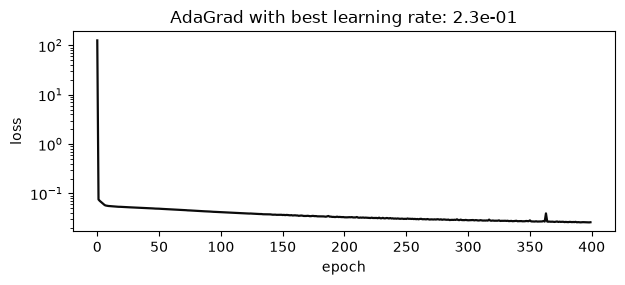

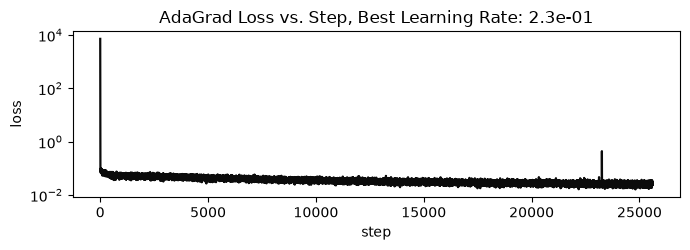

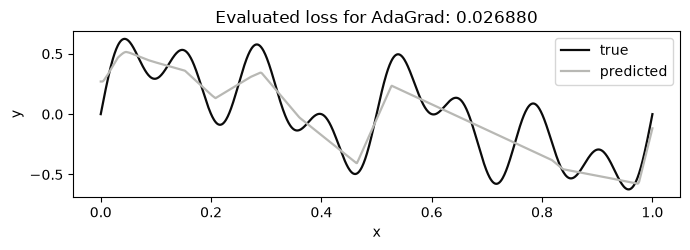

In [13]:
present_data(adagrad_losses, adagrad_mlp, adagrad_best_lr, "AdaGrad")

### E. Adam

In [14]:
@jax.jit
def adam_update(params, x, y, m_old, s_old, step, lr=1e-3, beta1=0.9, beta2=0.999, epsilon=EPSILON):
    g = jax.grad(loss_fn)(params, x, y)
    m_new = [(beta1 * m_w + (1 - beta1) * dw, beta1 * m_b + (1 - beta1) * db) for (m_w, m_b), (dw, db) in zip(m_old, g)]
    m = [(m_w / (1 - beta1 ** step), m_b / (1 - beta1 ** step)) for (m_w, m_b) in m_new]

    s_new = [(beta2 * s_w + (1 - beta2) * (dw ** 2), beta2 * s_b + (1 - beta2) * (db ** 2)) for (s_w, s_b), (dw, db) in zip(s_old, g)]
    s = [(s_w / (1 - beta2 ** step), s_b / (1 - beta2 ** step)) for (s_w, s_b) in s_new]
    params = [(w - lr * m_w / (jnp.sqrt(s_w + epsilon)), b - lr * m_b / (jnp.sqrt(s_b + epsilon))) for (w, b), (m_w, m_b), (s_w, s_b) in zip(params, m, s)]
    return params, m_new, s_new

NUM_PLOTS = 10
t = np.linspace(0, 1, 1000)
t_epochs = np.unique(np.geomspace(1, 400, NUM_PLOTS).astype(int))
t_epochs = t_epochs.astype(int)
def train_loop_with_adam(key, params, n_epochs=400, batch_size=128, n_batches = 64, lr=1e-3):
    losses = np.zeros((n_epochs, n_batches))
    step = 0
    m = [(jnp.zeros_like(w), jnp.zeros_like(b)) for w, b in params]
    s = [(jnp.zeros_like(w), jnp.zeros_like(b)) for w, b in params]
    y = np.zeros((len(t_epochs), 1000))

    for epoch in range(n_epochs):
        key, subkey = jax.random.split(key)
        x_batches_flat = jnp.reshape(X_dataset, (n_batches * batch_size, 1))
        y_batches_flat = jnp.reshape(Y_dataset, (n_batches * batch_size, 1))

        # Shuffle the batches for each epoch
        perm = jax.random.permutation(subkey, n_batches * batch_size)
        x_batches_flat = x_batches_flat[perm]
        y_batches_flat = y_batches_flat[perm]

        # Reshape back to batches
        X_batches = jnp.reshape(x_batches_flat, (n_batches, batch_size, 1))
        Y_batches = jnp.reshape(y_batches_flat, (n_batches, batch_size, 1))

        avg_loss = 0
        for i in range(n_batches):
            step += 1
            x_batch = X_batches[i]
            y_batch = Y_batches[i]
            params, m, s = adam_update(params, x_batch, y_batch, m, s, step, lr=lr)
            loss = loss_fn(params, x_batch, y_batch)
            avg_loss += loss
            losses[epoch, i] = loss
        print(f"\repoch {epoch + 1}/{n_epochs}, average loss: {float(avg_loss) / n_batches:.6f}", end="")

        if epoch + 1 in t_epochs:
            y[np.where(t_epochs == epoch + 1)[0][0],:] = np.array(forward(params, t[:,None])[:,0])

    return params, losses, y


adam_mlp_loss_vs_lr = []
min_loss = np.inf
adam_best_lr = None
y = None
for lr_r in lrs:
    final_mlp, final_losses, final_y = train_loop_with_adam(jax.random.key(2), mlp, n_epochs=400, n_batches=N_BATCHES, batch_size=BATCH_SIZE, lr=lr_r)
    final_loss = np.mean(final_losses[-1])

    if final_loss < min_loss:
        min_loss = final_loss
        adam_best_lr = lr_r
        adam_mlp = final_mlp
        adam_losses = final_losses
        y = final_y
    adam_mlp_loss_vs_lr.append(final_loss)
    print(f"\r lr: {lr_r:.1e}, final loss: {final_loss:.6f}")

print(f"Best learning rate for Adam: {adam_best_lr:.1e}, final loss: {min_loss:.6f}")

 lr: 1.0e+01, final loss: 0.20658358374000000
 lr: 2.8e+00, final loss: 0.13400500500000
 lr: 8.1e-01, final loss: 0.12789489402
 lr: 2.3e-01, final loss: 0.055939939
 lr: 6.6e-02, final loss: 0.020893893
 lr: 1.9e-02, final loss: 0.015116116
 lr: 5.3e-03, final loss: 0.004036036
 lr: 1.5e-03, final loss: 0.014808808
 lr: 4.3e-04, final loss: 0.016630630
 lr: 1.2e-04, final loss: 0.049799799
 lr: 3.5e-05, final loss: 0.055586586
 lr: 1.0e-05, final loss: 0.055735735
Best learning rate for Adam: 5.3e-03, final loss: 0.004036


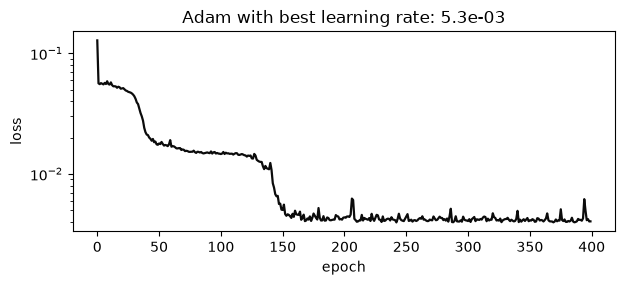

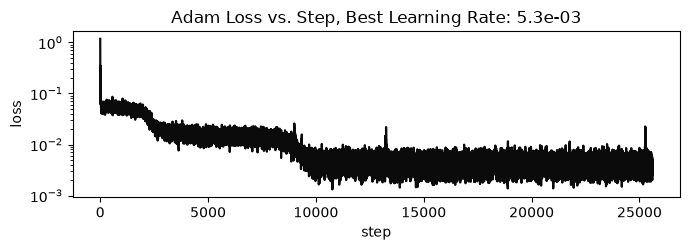

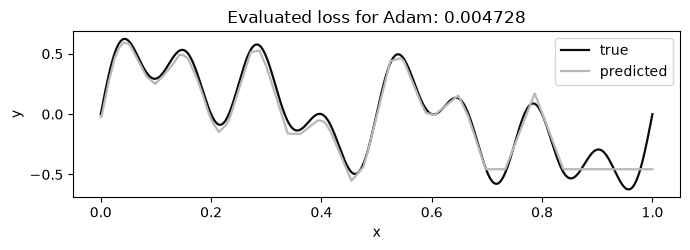

In [15]:
present_data(adam_losses, adam_mlp, adam_best_lr, "Adam")

### F. Muon - Skipped

---
## 4. What to report

- **All six loss curves on one set of axes**, log scale on y. Plot against both epochs and steps

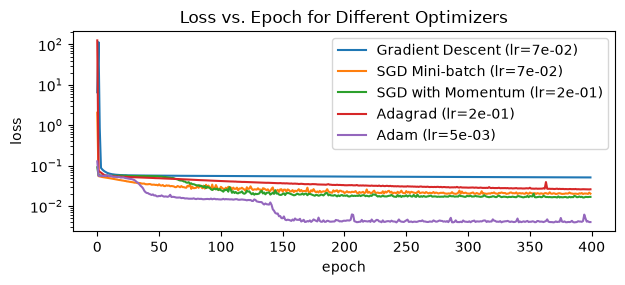

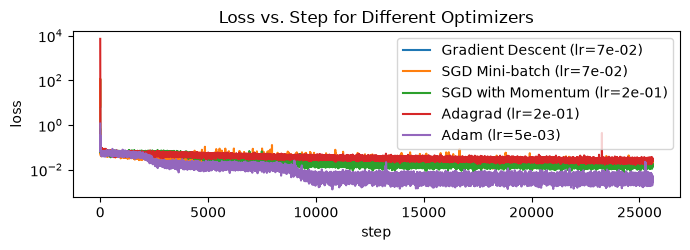

In [16]:
losses = [grad_descent_losses,sgd_minibatch_losses, sgd_momentum_losses, adagrad_losses, adam_losses]
labels = ["Gradient Descent", "SGD Mini-batch", "SGD with Momentum", "Adagrad", "Adam"]
final_lrs = [grad_descent_best_lr, sgd_minibatch_best_lr, sgd_momentum_best_lr, adagrad_best_lr, adam_best_lr]
fig_epoch, ax_epoch = plt.subplots(figsize=(7, 2.6))
fig_step, ax_step = plt.subplots(figsize=(7, 2.6))
for loss, label, final_lr in zip(losses, labels, final_lrs):
    ax_epoch.plot(np.mean(loss, axis=1), label=f"{label} (lr={final_lr:.0e})")
    ax_step.plot(loss.flatten(), label=f"{label} (lr={final_lr:.0e})")
ax_epoch.set_xlabel("epoch")
ax_epoch.set_ylabel("loss")
ax_epoch.set_yscale("log")
# ax_epoch.set_xscale("log")
ax_epoch.set_title("Loss vs. Epoch for Different Optimizers")
ax_epoch.legend()
plt.tight_layout()

ax_step.set_xlabel("step")
ax_step.set_ylabel("loss")
ax_step.set_yscale("log")
# ax_step.set_xscale("log")
ax_step.set_title("Loss vs. Step for Different Optimizers")
ax_step.legend()
plt.tight_layout()

---
## 5. One more plot

Now make a plot I did not ask for.



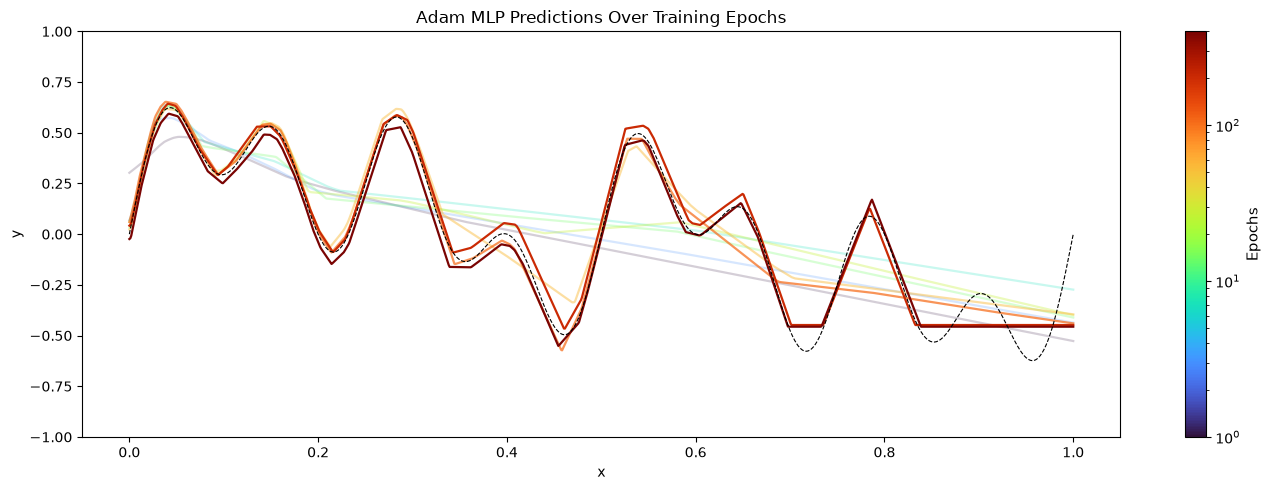

In [22]:
fig, ax = plt.subplots(figsize=(14, 5))

#Use logarithmic color scale to represent the epochs in the plot
cmap = plt.colormaps['turbo'] 

from matplotlib import colors as mcolors
norm = mcolors.LogNorm(vmin=1, vmax=400)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([]) # Placeholder required by the colorbar engine

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Epochs', fontsize=11)

for i, (epoch, y_sample) in enumerate(zip(t_epochs, y)):
    ax.plot(t, y_sample, color=cmap(norm(epoch)), lw=1.6, alpha =min(epoch / 200 + 0.2, 1.0))

ax.plot(t, target_fn(t), color="black", lw=0.8, linestyle="--", label="target function")
# ax.legend()
ax.set_ylim(-1.0, 1.0)
ax.set_xlabel("x"); ax.set_ylabel("y"); 
ax.set_title("Adam MLP Predictions Over Training Epochs")
plt.tight_layout(); plt.show()


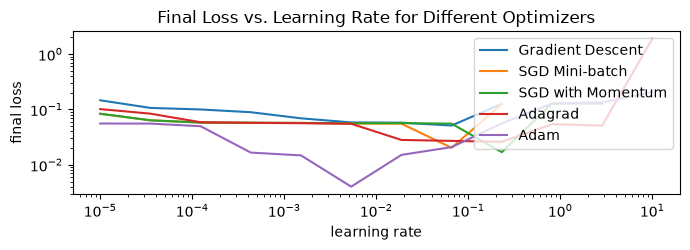

In [18]:
loss_vs_lr = [grad_descent_loss_vs_lr, sgd_minibatch_losses_vs_lr, sgd_momentum_loss_vs_lr, adagrad_mlp_loss_vs_lr, adam_mlp_loss_vs_lr]
fig, ax = plt.subplots(figsize=(7, 2.6))
for loss, label in zip(loss_vs_lr, labels):
    ax.plot(lrs, loss, label=label)
ax.set_xlabel("learning rate")
ax.set_ylabel("final loss")
ax.set_xscale("log")
ax.set_yscale("log")
ax.legend()
ax.set_title("Final Loss vs. Learning Rate for Different Optimizers")
plt.tight_layout(); plt.show()

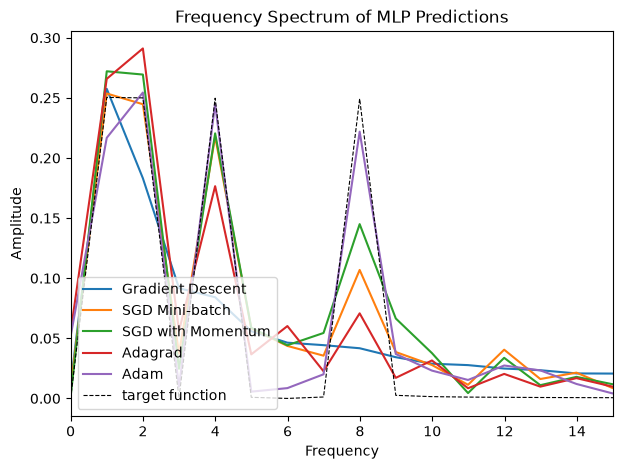

In [21]:
mlps = [grad_descent_mlp, sgd_minibatch_mlp, sgd_momentum_mlp, adagrad_mlp, adam_mlp]

fig, ax = plt.subplots(figsize=(7, 5))
for mlp_i, label in zip(mlps, labels):
    y_pred = np.array(forward(mlp_i, t[:, None]))[:, 0]
    freqs = np.fft.fftfreq(len(t), d=(t[1] - t[0]))
    y_fft = np.fft.fft(y_pred)
    ax.plot(freqs[:len(freqs)//2], np.abs(y_fft)[:len(freqs)//2] * 2 / len(t), label=label)

y_true = np.array(target_fn(t))
freqs = np.fft.fftfreq(len(t), d=(t[1] - t[0]))
y_true_fft = np.fft.fft(y_true)
ax.plot(freqs[:len(freqs)//2], np.abs(y_true_fft)[:len(freqs)//2] * 2 / len(t), color="black", lw=0.8, linestyle="--", label="target function")
ax.set_xlim(0, 15)
ax.set_xlabel("Frequency")
ax.set_ylabel("Amplitude")
ax.set_title("Frequency Spectrum of MLP Predictions")
ax.legend(loc="lower left")
plt.show()

# Analysis / Comments

- Adam has the best final loss at 0.004, while others reach ~0.017-0.05.
- Adam has two step-like drops in loss. As the optimizer approaches a local minimum, the gradient shrinks, and the exponential moving average gradually updates to increase the effective-learning rate in tandem with these smaller gradients. This allows the optimizer to navigate these finer loss landscapes
- Gradient descent is only able to fit frequency 1 and some of frequency 2.
- Each successive method is better at fitting the higher-frequencies, this is clear in the time-domain, which shows that models start-out flat and better match the higher-frequency data components over time
- Adam has some flat regions near x = 0.72 and > 0.84. This could be an artifact from the Relu being unable to achieve sensitivity near these inputs.
- The FFT plot shows that all methods fit frequencies 1, 2, and 4. Only Adam approached capturing frequency 8. 
